# Hands-On Data Lab: Retail Sales Analysis
**Data Analyst Internship, Task 2**

This notebook sets up a working data analysis environment and completes practical exercises in
data manipulation, visualisation, and basic analysis on a synthetic retail sales dataset
(`sales_data.csv`, generated by `generate_data.py`).

**Contents**
1. Environment check
2. Load and inspect the data
3. Clean the data
4. Data manipulation (feature engineering, filtering, grouping, pivoting)
5. Visualisation
6. Basic analysis (correlation, hypothesis test, regression)
7. Findings

## 1. Environment check
Confirm Python and the required libraries are installed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("pandas    :", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn   :", sns.__version__)

sns.set_theme(style="whitegrid")
np.random.seed(42)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

Python    : 3.12.3
NumPy     : 2.4.4
pandas    : 3.0.2
Matplotlib: 3.10.8
Seaborn   : 0.13.2


## 2. Load and inspect the data

In [2]:
df = pd.read_csv("sales_data.csv", parse_dates=["order_date"])
print("Shape:", df.shape)
df.head()

Shape: (512, 10)


,order_id,order_date,region,category,product,units,unit_price,discount,customer_age,payment_method
0,1301,2026-07-05,East,Clothing,T-Shirt,5,599.51,0.15,21.0,Cash
1,1232,2026-03-27,North,Electronics,Smartwatch,5,5756.57,0.10,44.0,Net Banking
2,1051,2026-05-06,East,Clothing,T-Shirt,2,592.05,0.05,30.0,Card
3,1305,2026-10-10,West,Electronics,Headphones,1,2531.66,0.00,30.0,Card
4,1470,2026-07-14,South,Home,Bedsheet,2,1184.61,0.05,28.0,UPI


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 512 entries, 0 to 511
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        512 non-null    int64         
 1   order_date      512 non-null    datetime64[us]
 2   region          501 non-null    str           
 3   category        512 non-null    str           
 4   product         512 non-null    str           
 5   units           512 non-null    int64         
 6   unit_price      512 non-null    float64       
 7   discount        512 non-null    float64       
 8   customer_age    497 non-null    float64       
 9   payment_method  504 non-null    str           
dtypes: datetime64[us](1), float64(3), int64(2), str(4)
memory usage: 40.1 KB


In [4]:
df.describe().round(2)

,order_id,order_date,units,unit_price,discount,customer_age
count,512.00,512,512.00,512.00,512.00,497.00
mean,1249.30,2026-06-03 22:52:30,2.99,2197.68,0.05,33.39
min,1000.00,2026-01-01 00:00:00,1.00,238.09,0.00,18.00
25%,1123.75,2026-03-15 00:00:00,2.00,863.81,0.00,25.00
50%,1249.50,2026-06-11 00:00:00,3.00,1829.03,0.00,33.00
75%,1373.25,2026-08-20 06:00:00,4.00,3187.80,0.10,41.00
max,1499.00,2026-10-27 00:00:00,5.00,6291.32,0.15,68.00
std,144.70,NaN,1.40,1644.08,0.06,10.23


In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
order_id           0
order_date         0
region            11
category           0
product            0
units              0
unit_price         0
discount           0
customer_age      15
payment_method     8
dtype: int64

Duplicate rows: 12


## 3. Clean the data
Three problems were found: duplicate rows, missing `customer_age`, and missing `region` / `payment_method`.
- Duplicates are removed.
- Missing ages are filled with the **median** (robust to outliers).
- Missing categories are labelled **"Unknown"** so no rows are lost.

In [6]:
clean = df.drop_duplicates().copy()
clean["customer_age"] = clean["customer_age"].fillna(clean["customer_age"].median())
clean["region"] = clean["region"].fillna("Unknown")
clean["payment_method"] = clean["payment_method"].fillna("Unknown")

print("Rows before:", len(df), "| after:", len(clean))
print("Missing values left:", int(clean.isna().sum().sum()))

Rows before: 512 | after: 500
Missing values left: 0


## 4. Data manipulation

### 4.1 Feature engineering
Create revenue (after discount), month, and an age-group column.

In [7]:
clean["revenue"] = clean["units"] * clean["unit_price"] * (1 - clean["discount"])
clean["month"] = clean["order_date"].dt.to_period("M").astype(str)
clean["age_group"] = pd.cut(
    clean["customer_age"], bins=[17, 25, 35, 50, 100],
    labels=["18-25", "26-35", "36-50", "51+"]
)
clean[["order_id", "category", "units", "unit_price", "discount", "revenue", "month", "age_group"]].head()

,order_id,category,units,unit_price,discount,revenue,month,age_group
0,1301,Clothing,5,599.51,0.15,2547.9175,2026-07,18-25
1,1232,Electronics,5,5756.57,0.10,25904.5650,2026-03,36-50
2,1051,Clothing,2,592.05,0.05,1124.8950,2026-05,26-35
3,1305,Electronics,1,2531.66,0.00,2531.6600,2026-10,26-35
4,1470,Home,2,1184.61,0.05,2250.7590,2026-07,26-35


### 4.2 Filtering and sorting
Top 5 individual orders by revenue.

In [8]:
top5 = clean.sort_values("revenue", ascending=False).head(5)
top5[["order_id", "region", "category", "product", "units", "revenue"]].round(2)

,order_id,region,category,product,units,revenue
388,1039,South,Electronics,Smartwatch,5,30890.45
203,1016,South,Electronics,Smartwatch,5,30599.10
450,1487,North,Electronics,Smartwatch,5,29167.45
182,1292,North,Electronics,Smartwatch,5,28722.15
456,1257,North,Electronics,Smartwatch,5,28494.11


### 4.3 Grouping and aggregation

In [9]:
by_category = (clean.groupby("category")
               .agg(orders=("order_id", "count"),
                    units=("units", "sum"),
                    revenue=("revenue", "sum"),
                    avg_order_value=("revenue", "mean"))
               .sort_values("revenue", ascending=False)
               .round(2))
by_category

,orders,units,revenue,avg_order_value
category,,,,
Electronics,136,404,1546103.19,11368.41
Clothing,158,493,845804.57,5353.19
Home,126,381,635023.96,5039.87
Books,80,211,97483.07,1218.54


In [10]:
by_region = (clean.groupby("region")["revenue"]
             .agg(["count", "sum", "mean"]).round(2)
             .sort_values("sum", ascending=False))
by_region

,count,sum,mean
region,,,
East,133,871744.10,6554.47
North,117,792857.63,6776.56
South,120,740351.35,6169.59
West,120,673983.56,5616.53
Unknown,10,45478.15,4547.82


### 4.4 Pivot table
Total revenue for each category in each region (in thousands).

In [11]:
pivot = clean.pivot_table(index="category", columns="region",
                          values="revenue", aggfunc="sum").div(1000).round(1)
pivot

region,East,North,South,Unknown,West
category,,,,,
Books,24.7,14.2,21.9,1.7,35.0
Clothing,237.2,209.7,174.0,23.1,201.8
Electronics,381.9,409.1,414.4,7.0,333.6
Home,228.0,159.8,130.1,13.6,103.6


## 5. Visualisation

### 5.1 Revenue by category (bar chart)

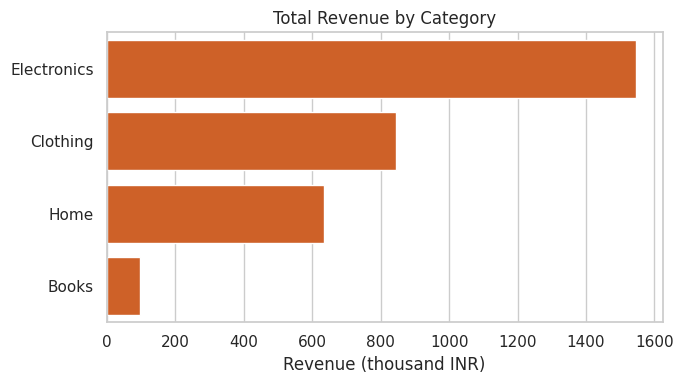

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
order = by_category.index
sns.barplot(x=by_category["revenue"] / 1000, y=order, ax=ax, color="#EA580C")
ax.set_title("Total Revenue by Category")
ax.set_xlabel("Revenue (thousand INR)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figures/fig1_revenue_by_category.png", dpi=150)
plt.show()

### 5.2 Monthly revenue trend (line chart)
Note that October covers only the days up to 27 October, so it is slightly incomplete.

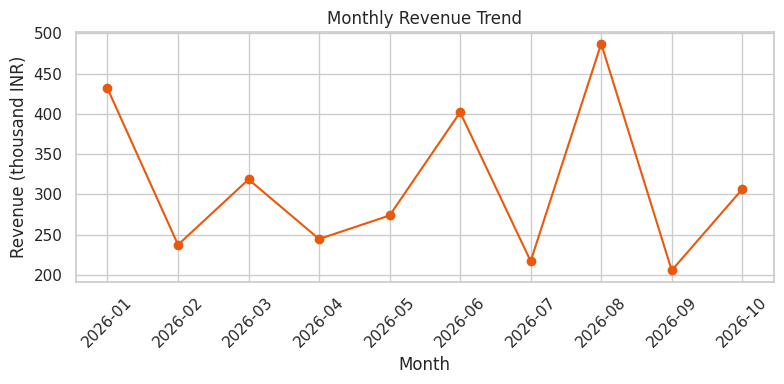

In [13]:
monthly = clean.groupby("month")["revenue"].sum() / 1000
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="#EA580C")
ax.set_title("Monthly Revenue Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/fig2_monthly_revenue.png", dpi=150)
plt.show()

### 5.3 Distribution of customer age (histogram)

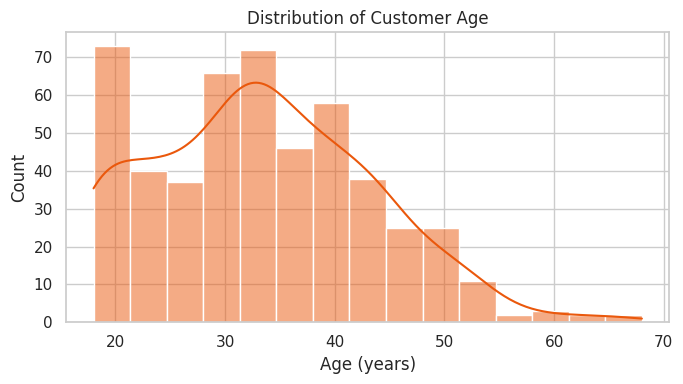

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(clean["customer_age"], bins=15, kde=True, ax=ax, color="#EA580C")
ax.set_title("Distribution of Customer Age")
ax.set_xlabel("Age (years)")
plt.tight_layout()
plt.savefig("figures/fig3_age_distribution.png", dpi=150)
plt.show()

### 5.4 Order revenue by region (box plot)

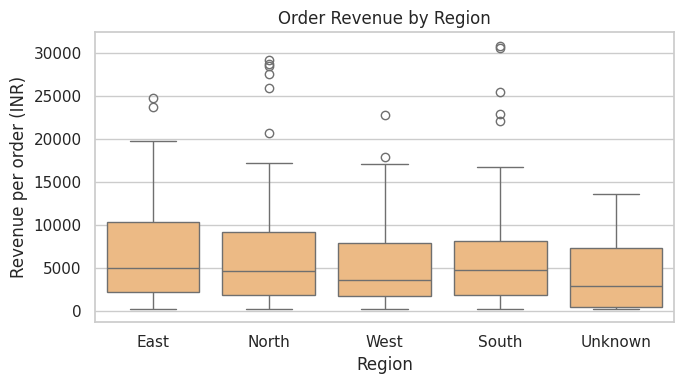

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=clean, x="region", y="revenue", ax=ax, color="#FDBA74")
ax.set_title("Order Revenue by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Revenue per order (INR)")
plt.tight_layout()
plt.savefig("figures/fig4_revenue_by_region.png", dpi=150)
plt.show()

### 5.5 Correlation heatmap

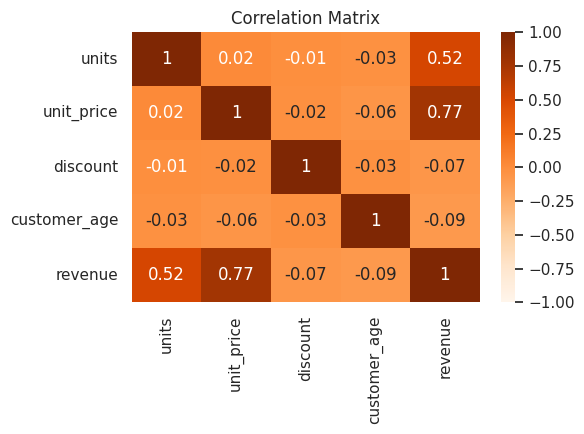

In [16]:
num_cols = ["units", "unit_price", "discount", "customer_age", "revenue"]
corr = clean[num_cols].corr().round(2)
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="Oranges", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.savefig("figures/fig5_correlation_heatmap.png", dpi=150)
plt.show()

## 6. Basic analysis

### 6.1 Correlation
Which numeric variables move together with revenue?

In [17]:
print(corr["revenue"].drop("revenue").sort_values(ascending=False))

unit_price      0.77
units           0.52
discount       -0.07
customer_age   -0.09
Name: revenue, dtype: float64


### 6.2 Hypothesis test: do discounted orders contain more units?
- H0: mean units per order is the same for discounted and non-discounted orders.
- H1: the means differ.

A two-sample Welch t-test is used (it does not assume equal variances).

In [18]:
disc = clean.loc[clean["discount"] > 0, "units"]
nodisc = clean.loc[clean["discount"] == 0, "units"]
t, p = stats.ttest_ind(disc, nodisc, equal_var=False)

print(f"Discounted orders    : n={len(disc)}, mean units={disc.mean():.2f}")
print(f"Non-discounted orders: n={len(nodisc)}, mean units={nodisc.mean():.2f}")
print(f"Welch t = {t:.3f}, p = {p:.4f}")
print("Reject H0 at 0.05?", p < 0.05)

Discounted orders    : n=240, mean units=2.95
Non-discounted orders: n=260, mean units=3.00
Welch t = -0.364, p = 0.7164
Reject H0 at 0.05? False


### 6.3 Simple linear regression: revenue vs units
Fit `revenue = slope * units + intercept` and check how much variance is explained (R squared).

In [19]:
res = stats.linregress(clean["units"], clean["revenue"])
print(f"Slope     : {res.slope:,.1f} INR per extra unit")
print(f"Intercept : {res.intercept:,.1f}")
print(f"R squared : {res.rvalue**2:.3f}")
print(f"p-value   : {res.pvalue:.2e}")

Slope     : 2,121.0 INR per extra unit
Intercept : -67.6
R squared : 0.267
p-value   : 1.57e-35


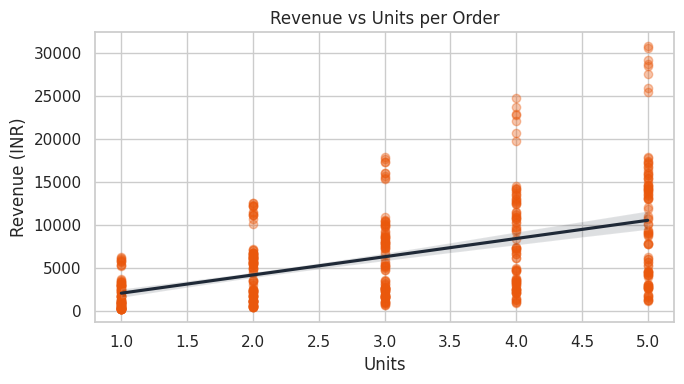

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=clean, x="units", y="revenue", ax=ax,
            scatter_kws={"alpha": 0.35, "color": "#EA580C"}, line_kws={"color": "#1F2937"})
ax.set_title("Revenue vs Units per Order")
ax.set_xlabel("Units")
ax.set_ylabel("Revenue (INR)")
plt.tight_layout()
plt.savefig("figures/fig6_regression.png", dpi=150)
plt.show()

### 6.4 Customer segments by age group

In [21]:
seg = (clean.groupby("age_group", observed=True)["revenue"]
       .agg(orders="count", total="sum", average="mean").round(0))
seg

,orders,total,average
age_group,,,
18-25,129,871325.0,6754.0
26-35,171,1082129.0,6328.0
36-50,173,1029669.0,5952.0
51+,27,141291.0,5233.0


## 7. Findings

In [22]:
top_cat = by_category.index[0]
top_reg = by_region.index[0]
best_month = monthly.idxmax()
print(f"Top category by revenue : {top_cat} ({by_category.loc[top_cat, 'revenue']/1000:,.0f}k INR)")
print(f"Top region by revenue   : {top_reg}")
print(f"Best month              : {best_month} ({monthly.max():,.0f}k INR)")
print(f"Total revenue           : {clean['revenue'].sum()/1e6:.2f} million INR across {len(clean)} orders")

Top category by revenue : Electronics (1,546k INR)
Top region by revenue   : East
Best month              : 2026-08 (487k INR)
Total revenue           : 3.12 million INR across 500 orders


**Summary.** After removing duplicates and handling missing values, the exercises covered feature
engineering, grouping, pivoting, six charts, a correlation analysis, a hypothesis test, and a
regression. Revenue is driven mainly by item price and units per order, while discounts show
little relationship with order size in this dataset. All results are reproducible because the data
generator and random seed are included in the repository.